# Parte 1 – Recolección de noticias

## 1.1. Configuración inicial

**Enunciado**: Registrar la fecha de descarga, el medio elegido (A, B o C) y las URLs base en la primera celda Markdown.

Las noticias se descargarán entre el 16 y 17 de octubre de 2026 del diario La República (opción A). Los enlaces a descargar son:

- sitio: https://larepublica.pe
- robots.txt: https://larepublica.pe/robots.txt
- RSS: 
  - https://larepublica.pe/rss/politica.xml
  - https://larepublica.pe/rss/economia.xml
  - https://larepublica.pe/rss/deportes.xml
  - https://larepublica.pe/rss/ciencia.xml

En una primera revisión, con ayuda de Claude, se identificó que solo se iban a recolectar 60 noticias de los últimos días, por lo cual, se tomará la estrategia de rastrear más noticias de los enlaces de cada nota.

Sobre la categoría Ciencia y tecnología, en el diario La República tiene ambas secciones por separado, por lo cual, eventualmente, ambas se agruparán en la categoría ciencia_tecnologia.

## 1.2. Extracción

**Enunciado**: Extraer mínimo 350 noticias con las columnas: titular, bajada, medio, seccion_original, url, fecha. Usar RSS o HTML (requests + BeautifulSoup), implementando pausas entre peticiones y guardando respaldo crudo en datos/raw/.

Para ello, primero se revisará robots.txt.

In [1]:
import requests

HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; TareaPythonIntermedio/1.0; +https://github.com/Clandra91/Python_intermedio)"}

respuesta = requests.get("https://larepublica.pe/robots.txt", headers=HEADERS, timeout=20)
print("Código:", respuesta.status_code)

for linea in respuesta.text.splitlines():
    if linea.startswith(("Allow", "Disallow", "Crawl-delay")):
        print(linea)

Código: 200
Disallow: /buscador*
Disallow: /data
Disallow: /data/*
Disallow: /contactenos
Disallow: /*/pag/
Disallow: /*/pag/*
Disallow: /*/*/page/*
Disallow: /archive/*
Disallow: /archivo/*
Disallow: /node/*
Disallow: /taxonomy/term/*
Disallow: /assets/*
Disallow: /files/*
Disallow: /comment/reply/*
Disallow: /envivo/*
Disallow: /*/tag/*
Disallow: */*Perú
Disallow: */Encuesta*
Disallow: */EMPRESA/*
Disallow: *ref=photogallery*
Disallow: */sitemaps/*
Disallow: */pf/*
Allow: /sitemap/
Allow: /sitemap/*
Allow: /sitemaps/*
Allow: /rss/
Allow: /rss/*


Se pueden consultar los RSS y los sitemaps, pero no se podrá consultar en el buscador, la paginación de las secciones, encuestas, entre otros.

Las páginas de cada nota (como /economia/2026/10/16/) no están prohibidos, así que se pueden visitar. Además, no hay Crawl-delay, pero se van a agregar pausas.

Ahora, se va a definir la pausa de 1 a 2 segundos (1.5 segundos entre cada intento), además de delimitar máximo 1 reintento (2 pedidos), de acuerdo con lo indicado en la tarea.

In [2]:
import time

PAUSA = 1.5  # segundos de espera después de cada pedido

def descargar(url):
    """Descarga una URL con pausa y, si falla, 1 reintento."""
    for intento in range(2):  # intento 0 = primer pedido; intento 1 = el reintento
        try:
            respuesta = requests.get(url, headers=HEADERS, timeout=20)
            time.sleep(PAUSA)
            if respuesta.status_code == 200:
                return respuesta
            print("Código", respuesta.status_code, "en", url)
        except requests.RequestException as error:
            time.sleep(PAUSA)
            print("Error de conexión:", error)
    return None  # si los 2 intentos fallan, devuelve None


In [3]:
descargar("https://larepublica.pe/rss/ciencia.xml")

<Response [200]>

Ahora, se procede a leer un RSS y guardarlo como respaldo, para hacer una primera prueba con la categoría política.

In [4]:
from datetime import date

fecha_descarga = date.today().isoformat()  # ej. "2026-10-16"

respuesta = descargar("https://larepublica.pe/rss/politica.xml")

# Se guarda el archivo tal como llegó (respaldo crudo)
ruta = f"datos/raw/rss_politica_{fecha_descarga}.xml"
with open(ruta, "wb") as archivo:
    archivo.write(respuesta.content)
print("Guardado:", ruta)


Guardado: datos/raw/rss_politica_2026-10-16.xml


In [5]:
from bs4 import BeautifulSoup

sopa = BeautifulSoup(respuesta.content, "xml")
items = sopa.find_all("item")
print("Noticias en el feed:", len(items))
items[0]


Noticias en el feed: 28


<item>
<title>
                                 Alejandro Aguinaga viajó a Argentina el martes 13 de octubre y todavía no regresa pese a debate por facultades 
                            </title>
<link>https://larepublica.pe/politica/2026/10/16/alejandro-aguinaga-viajo-a-argentina-el-martes-13-de-octubre-y-todavia-no-regresa-pese-a-debate-por-facultades-hnews-512448</link>
<guid isPermaLink="true">https://larepublica.pe/politica/2026/10/16/alejandro-aguinaga-viajo-a-argentina-el-martes-13-de-octubre-y-todavia-no-regresa-pese-a-debate-por-facultades-hnews-512448</guid>
<description>  
                             Según su registro en Migraciones, su salida del país fue el 13 de octubre, en plena discusión del pedido de facultades legislativas del Ejecutivo. Es su tercer viaje al exterior este año, tras Panamá en enero y Estados Unidos en agosto. 
                            </description>
<image:image>
<image:loc>https://larepublica.cronosmedia.glr.pe/original/2026/10/16/6ad2dde6c07d25

Para poder visualizar mejor el resultado se pasará a una tabla.

In [6]:
import pandas as pd

filas = []  # Se crea una lista vacía, donde irá una noticia por elemento

for item in items:
    url = item.find("link").get_text(strip=True)

    # Se arma un diccionario con las 6 columnas de esta noticia
    noticia = {
        "titular": item.find("title").get_text(strip=True),
        "bajada": item.find("description").get_text(strip=True),
        "medio": "La Republica",
        "seccion_original": url.split("/")[3],
        "url": url,
        "fecha": "-".join(url.split("/")[4:7]),
    }
    filas.append(noticia)  # Se agrega la noticia a la lista

rss_politica = pd.DataFrame(filas)
print(rss_politica.shape)
rss_politica.head()

(28, 6)


,titular,bajada,medio,seccion_original,url,fecha
0,Alejandro Aguinaga viajó a Argentina el martes...,"Según su registro en Migraciones, su salida de...",La Republica,politica,https://larepublica.pe/politica/2026/10/16/ale...,2026-10-16
1,Álvaro Vargas Llosa niega intromisión política...,Vargas Llosa afirma que la soberanía peruana n...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/alv...,2026-10-16
2,Solicitan la destitución de Roberto Burneo por...,"La asociación civil Iniciativa Democrática, or...",La Republica,politica,https://larepublica.pe/politica/2026/10/16/sol...,2026-10-16
3,Puno: alcalde de Quiaca muere tras caer a un b...,El cuerpo de Ricardo Quispe presentaba múltipl...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/pun...,2026-10-16
4,Ministro Rafael Belaúnde propone que las FF.AA...,El titular del Ministerio de Defensa explicó q...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/min...,2026-10-16


Como se observa, se obtuvieron 28 noticias, y se logró completar las  columnas requeridas. 

Además, como se indicó previamente, debido a que no se logrará recabar la cantidad de noticias requeridas para esta tarea buscando solamente a través del RSS, se procederá a rastrear más noticias a través de los enlaces. Por ello, la información de las fechas y sección (política, economía, etc.), se extraerán del enlace (URL).

Luego de realizar la prueba, se procede a repetirlo con las 4 secciones: política, economía, deportes, ciencia.

In [12]:
import re
def fecha_desde_url(url):
    """Busca en la URL el patrón /AAAA/MM/DD/ y lo devuelve como AAAA-MM-DD."""
    encontrado = re.search(r"/(\d{4})/(\d{2})/(\d{2})/", url)
    if encontrado:
        return "-".join(encontrado.groups())
    return None

In [14]:
SECCIONES_RSS = ["politica", "economia", "deportes", "ciencia"]

def leer_rss(seccion):
    """Descarga el RSS de una sección, guarda el respaldo crudo y devuelve una tabla."""
    url_rss = f"https://larepublica.pe/rss/{seccion}.xml"
    respuesta = descargar(url_rss)
    if respuesta is None:
        print("No se pudo descargar:", url_rss)
        return pd.DataFrame()

    # Respaldo crudo
    with open(f"datos/raw/rss_{seccion}_{fecha_descarga}.xml", "wb") as archivo:
        archivo.write(respuesta.content)

    # Lectura de las noticias (igual que con política)
    sopa = BeautifulSoup(respuesta.content, "xml")
    filas = []
    for item in sopa.find_all("item"):
        url = item.find("link").get_text(strip=True)
        filas.append({
            "titular": item.find("title").get_text(strip=True),
            "bajada": item.find("description").get_text(strip=True),
            "medio": "La Republica",
            "seccion_original": url.split("/")[3],
            "url": url,
            "fecha": fecha_desde_url(url),
        })
    return pd.DataFrame(filas)

In [15]:
tablas = []
for seccion in SECCIONES_RSS:
    tabla = leer_rss(seccion)
    print(seccion, "->", len(tabla), "noticias")
    tablas.append(tabla)

rss = pd.concat(tablas, ignore_index=True)
print("Total desde RSS:", rss.shape)
rss["seccion_original"].value_counts()

politica -> 28 noticias
economia -> 13 noticias
deportes -> 11 noticias
ciencia -> 7 noticias
Total desde RSS: (59, 6)


seccion_original
politica    28
economia    13
deportes    11
ciencia      7
Name: count, dtype: int64

In [16]:
rss["fecha"].unique()

<StringArray>
['2026-10-16', '2026-10-15', '2026-02-14', '2026-10-13', '2026-10-14',
 '2026-08-21']
Length: 6, dtype: str

De acuerdo con lo que había anticipado Claude, no va a ser posible llegar a la cantidad de noticias que requiere la Tarea 1 (350), ya que solo se han obtenido 59 noticias. Por ello, se va a recurrir a leer los enlaces que hay en las 59 noticias identificadas.

Para ello, primero se definir las categorías que se va ratrear.

In [18]:
from urllib.parse import urljoin, urlsplit

# Secciones de La República que corresponden a las 4 categorías oficiales
SECCION_A_CATEGORIA = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}

# Forma de la URL de una nota: /seccion/(subseccion opcional)/AAAA/MM/DD/titulo
PATRON_NOTA = re.compile(r"^/(politica|economia|deportes|ciencia|tecnologia)(/[a-z0-9-]+)?/\d{4}/\d{2}/\d{2}/[a-z0-9-]+$")

TOPE_POR_CATEGORIA = 100  # para que ninguna categoría ahogue a las demás
MAX_PEDIDOS = 500         # para no cargar al sitio

def categoria_de(url):
    """Devuelve la categoría oficial según la sección de la URL."""
    return SECCION_A_CATEGORIA[url.split("/")[3]]

Al rastreo se le delimita un tope de 100 noticias por cateogrías, siendo el máximo resultado de 500 pedidos, y solo se siguen enlaces a notas de las 4 secciones, que robots.txt no prohíbe.

In [19]:
semillas = set(rss["url"])  # las notas del RSS
vistos = set(semillas)      # todas las URLs ya conocidas, para no repetir
cola = list(rss["url"])     # notas por visitar
nuevas = []                 # noticias nuevas encontradas por enlaces
pedidos = 0

# Se cuentan las noticias que ya hay por categoría (las del RSS)
conteo = {"politica": 0, "economia": 0, "deportes": 0, "ciencia_tecnologia": 0}
for url in rss["url"]:
    conteo[categoria_de(url)] += 1

while cola and pedidos < MAX_PEDIDOS and min(conteo.values()) < TOPE_POR_CATEGORIA:
    url = cola.pop(0)  # se toma la primera de la cola
    categoria = categoria_de(url)

    # Si su categoría ya está completa, no se visita (salvo las del RSS, que aportan enlaces)
    if url not in semillas and conteo[categoria] >= TOPE_POR_CATEGORIA:
        continue

    respuesta = descargar(url)
    pedidos += 1
    if respuesta is None:
        continue
    sopa = BeautifulSoup(respuesta.text, "lxml")

    # 1) Si es una nota nueva, se guardan sus datos
    if url not in semillas:
        titulo = sopa.find("meta", property="og:title")
        resumen = sopa.find("meta", property="og:description")
        nuevas.append({
            "titular": titulo["content"].strip() if titulo else None,
            "bajada": resumen["content"].strip() if resumen else None,
            "medio": "La Republica",
            "seccion_original": url.split("/")[3],
            "url": url,
            "fecha": fecha_desde_url(url),
        })
        conteo[categoria] += 1

    # 2) Se agregan a la cola los enlaces a otras notas de las 4 secciones
    for enlace in sopa.find_all("a", href=True):
        partes = urlsplit(urljoin("https://larepublica.pe", enlace["href"]))
        if partes.netloc != "larepublica.pe" or not PATRON_NOTA.match(partes.path):
            continue
        nueva_url = "https://larepublica.pe" + partes.path
        if nueva_url not in vistos and conteo[categoria_de(nueva_url)] < TOPE_POR_CATEGORIA:
            vistos.add(nueva_url)
            cola.append(nueva_url)

    if pedidos % 25 == 0:
        print(pedidos, "pedidos |", conteo)

print("Pedidos:", pedidos, "| Noticias nuevas:", len(nuevas))
print(conteo)

25 pedidos | {'politica': 28, 'economia': 13, 'deportes': 11, 'ciencia_tecnologia': 7}
50 pedidos | {'politica': 28, 'economia': 13, 'deportes': 11, 'ciencia_tecnologia': 7}
75 pedidos | {'politica': 43, 'economia': 13, 'deportes': 12, 'ciencia_tecnologia': 7}
100 pedidos | {'politica': 68, 'economia': 13, 'deportes': 12, 'ciencia_tecnologia': 7}
125 pedidos | {'politica': 89, 'economia': 17, 'deportes': 12, 'ciencia_tecnologia': 7}
150 pedidos | {'politica': 89, 'economia': 42, 'deportes': 12, 'ciencia_tecnologia': 7}
Error de conexión: ('Connection aborted.', ConnectionResetError(10054, 'Se ha forzado la interrupción de una conexión existente por el host remoto', None, 10054, None))
175 pedidos | {'politica': 89, 'economia': 66, 'deportes': 12, 'ciencia_tecnologia': 8}
200 pedidos | {'politica': 89, 'economia': 87, 'deportes': 13, 'ciencia_tecnologia': 11}
225 pedidos | {'politica': 89, 'economia': 87, 'deportes': 38, 'ciencia_tecnologia': 11}
Código 404 en https://larepublica.pe/cie

Ahora se procede a guardar el respaldo de la información rastreada, y se unen las 2 tablas.

In [20]:
enlaces = pd.DataFrame(nuevas)

# Respaldo crudo de lo rastreado
enlaces.to_csv(f"datos/raw/notas_por_enlaces_{fecha_descarga}.csv", index=False, encoding="utf-8-sig")

noticias = pd.concat([rss, enlaces], ignore_index=True)
print("Total:", noticias.shape)
noticias["seccion_original"].value_counts()

Total: (400, 6)


seccion_original
politica      100
economia      100
deportes      100
ciencia        99
tecnologia      1
Name: count, dtype: int64

Se logró rastrear 400 noticias del diario La República, correspondiente a las secciones política, economía, deportes, ciencia y tecnología. 

La tarea advierte que GitHub rechaza archivos de más de 100 MB, y al ejecutar el rastreo, el peso total de las páginas completas sería aproximadamente de 170 MB. Frente a ello, por recomendación de Claude, se guardará la información rastreada en archivo CSV, el cual pesa 170 KB.

## 1.3. Limpieza y normalización

**Enunciado**:
- Eliminación de duplicados por URL y titulares vacíos. 
- Mapeo explícito de seccion_original a las 4 categorías finales (politica, economia, deportes, ciencia_tecnologia), mostrando la tabla de equivalencias. 
- Reporte del número de noticias descartadas y motivos.

Primero se identifica si se ha recolectado noticias duplicadas. La tarea solicita identificar duplicidad de los enlaces (URL), pero además de ello, también se va a identificar la duplicidad de 2 títulos, aunque tengan diferente URL, con la finalidad de tener noticias únicas.

In [ ]:
total_inicial = len(noticias)

# 1) Duplicados por URL (lo pide la tarea)
dup_url = noticias.duplicated(subset="url").sum()
noticias = noticias.drop_duplicates(subset="url")

# 2) Titulares vacíos
vacios = noticias["titular"].isna() | (noticias["titular"].str.strip() == "")
n_vacios = vacios.sum()
noticias = noticias[~vacios]

# 3) Mismo titular con otra URL (la misma noticia publicada dos veces)
dup_titular = noticias.duplicated(subset="titular").sum()
noticias = noticias.drop_duplicates(subset="titular")

# 4) Mapeo explícito de la sección a las 4 categorías oficiales
noticias["etiqueta"] = noticias["seccion_original"].map(SECCION_A_CATEGORIA)
sin_categoria = noticias["etiqueta"].isna().sum()
noticias = noticias[noticias["etiqueta"].notna()].reset_index(drop=True)

print("Noticias al inicio:", total_inicial, "| al final:", len(noticias))

Noticias al inicio: 400 | al final: 399


Con los filtros de duplicidad de URL y título, se identifica que quedan 399 noticias únicas, que no se repiten.

Ahora, se va a crear la tabla de descarte, donde se muestra el detalle de qué tipo de duplicidad se identificó, así como si hay titulares vacíos y noticias que no pertenezcan a alguna de las 4 categorías definidas.

In [25]:
reporte_descartes = pd.DataFrame({
    "motivo": ["URL duplicada", "Titular vacío", "Mismo titular con otra URL", "Sección fuera de las 4 categorías"],
    "noticias_descartadas": [dup_url, n_vacios, dup_titular, sin_categoria],
})
reporte_descartes

,motivo,noticias_descartadas
0,URL duplicada,0
1,Titular vacío,0
2,Mismo titular con otra URL,1
3,Sección fuera de las 4 categorías,0


Ninguna URL se duplica, sin embargo, sí se ha identificado el mismo título en 2 URL, y uno de esos URL no se pudo descargar. Además, todas las noticias cuentan con título y todos corresponden a las 4 categorías definidas.


Por último, se muestra la tabla de mapeo, donde se muestra la cantidad de noticias por sección.

In [24]:
tabla_mapeo = noticias.groupby(["seccion_original", "etiqueta"]).size().reset_index(name="noticias")
tabla_mapeo

,seccion_original,etiqueta,noticias
0,ciencia,ciencia_tecnologia,99
1,deportes,deportes,99
2,economia,economia,100
3,politica,politica,100
4,tecnologia,ciencia_tecnologia,1


Entonces, se cuenta con 100 noticias de ciencia_tecnologia, 99 de deportes, 100 de economía y 100 de política, es decir, quedan 399 noticias después de la limpieza.

## 1.4. Análisis Exploratorio (EDA)

**Enunciado**: Generar 3 gráficos con Plotly Express:
- Distribución de noticias por categoría.
- Distribución de noticias por medio o rango de fechas.
- Histograma de longitud de caracteres de los titulares.

Cada gráfico debe tener un título que exprese la conclusión analítica, no solo la variable.

La finalidad de este pas es identificar visualmente com se distribuye la información recolectada. 

In [ ]:
#Configuración de Plotly para VS Code y GitHub
import plotly.express as px
import plotly.io as pio

# Interactivo en VS Code y, además, imagen PNG para que se vea en GitHub
pio.renderers.default = "vscode+png"


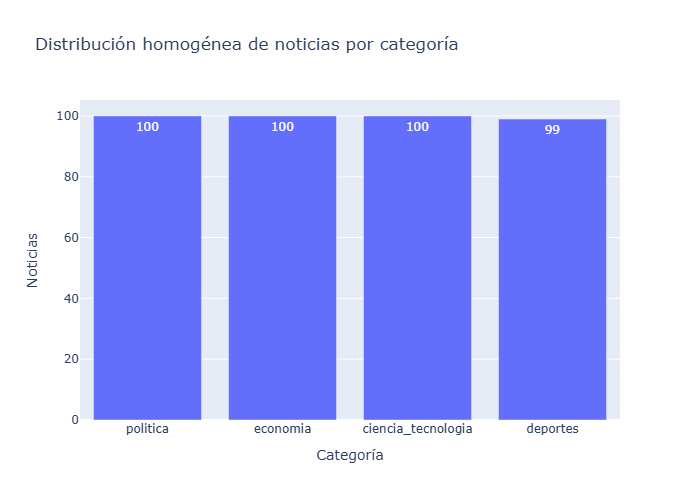

In [41]:
por_categoria = noticias["etiqueta"].value_counts().reset_index()
fig1 = px.bar(por_categoria, x="etiqueta", y="count", text="count",
              title="Distribución homogénea de noticias por categoría",
              labels={"etiqueta": "Categoría", "count": "Noticias"})
fig1.show()

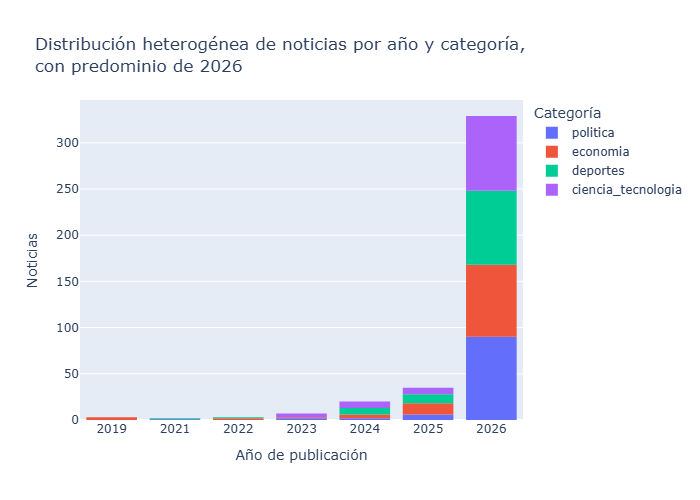

In [39]:
noticias["anio"] = noticias["fecha"].str[:4]  # "2026-10-16" → "2026"
fig2 = px.histogram(noticias, x="anio", color="etiqueta",
                    title="Distribución heterogénea de noticias por año y categoría,<br>con predominio de 2026",
                    labels={"anio": "Año de publicación", "etiqueta": "Categoría"})
fig2.update_xaxes(categoryorder="category ascending")
fig2.update_yaxes(title="Noticias")
fig2.show()


Se identifica que la distribución es casi homogénea entre las 4 categorías, ya que todas tienen 100 noticias, menos deportes, que tiene 99. Sobre la distribución de años, casi todas corresponden al año 2026, pero también hay de años anteriores, siendo el más antiguo, la noticia del año 2019. 

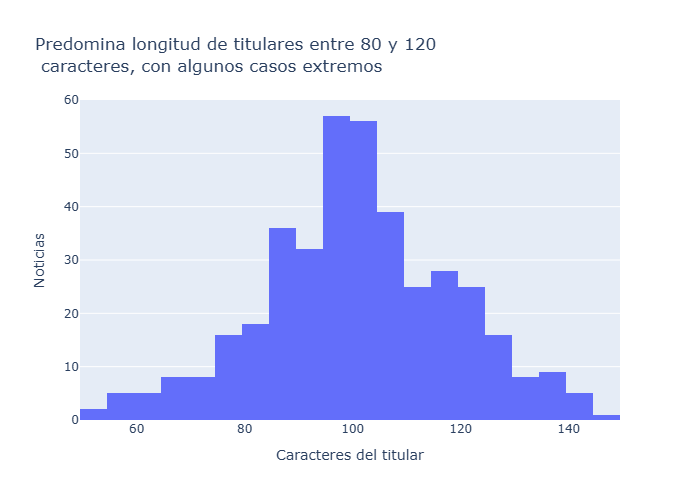

In [43]:
noticias["largo_titular"] = noticias["titular"].str.len()  # número de caracteres
fig3 = px.histogram(noticias, x="largo_titular", nbins=20,
                    title="Predomina longitud de titulares entre 80 y 120 <br> caracteres, con algunos casos extremos",
                    labels={"largo_titular": "Caracteres del titular"})
fig3.update_yaxes(title="Noticias")
fig3.show()


Del histograma se desprende que la mayoría de titulares mide entre 80 y 120 caracteres; además, el titular más corto tiene alrededor de 50, y el más largo, alrededor de 150.

## 1.5. Validación

**Enunciado**: Mostrar las 5 noticias con titulares más largos y más cortos, verificando coherencia con el histograma.

In [42]:
columnas = ["titular", "etiqueta", "largo_titular"]

print("Los 5 titulares más largos:")
display(noticias.nlargest(5, "largo_titular")[columnas])

print("Los 5 titulares más cortos:")
display(noticias.nsmallest(5, "largo_titular")[columnas])

Los 5 titulares más largos:


,titular,etiqueta,largo_titular
41,"Mia Shalit, arquera de Universitario, destaca ...",deportes,148
122,Produce: plataforma MAIA evoluciona para brind...,economia,142
220,"Ricardo Bettocchi, administrador de Melgar, co...",deportes,142
341,La Vinotinto de las Alturas ya tiene lista su ...,deportes,142
347,Luis Carlos Arias Schreiber: “Si Alejandro Olm...,deportes,142


Los 5 titulares más cortos:


,titular,etiqueta,largo_titular
115,Fugó cabecilla de la banda que mató a “China P...,politica,50
158,Movistar: Más de 100 comunidades rurales acced...,economia,53
108,Hackean cuenta de X del Ministerio de Economía...,politica,57
226,¿Cuándo inicia la Liga Peruana de Vóley Femeni...,deportes,57
119,Peritajes oficiales definirán juicio a los Sán...,politica,58


Se verifica la coherencia con el histograma: el titular más corto tiene 50 caracteres y el más largo 148, que coinciden con los bordes del gráfico (50 a 150). Además, los titulares que se visualizan en ambas tablas son completos, no se evidencia que se haya extraído la información a medias.

## 1.6. Exportación

**Enunciado**: Guardar datos/noticias.csv (7 columnas) y mostrar df.shape junto con las primeras 5 filas.

In [44]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]

df = noticias[COLUMNAS]
df.to_csv("datos/noticias.csv", index=False, encoding="utf-8-sig")

print(df.shape)
df.head()

(399, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Alejandro Aguinaga viajó a Argentina el martes...,"Según su registro en Migraciones, su salida de...",La Republica,politica,https://larepublica.pe/politica/2026/10/16/ale...,2026-10-16,politica
1,Álvaro Vargas Llosa niega intromisión política...,Vargas Llosa afirma que la soberanía peruana n...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/alv...,2026-10-16,politica
2,Solicitan la destitución de Roberto Burneo por...,"La asociación civil Iniciativa Democrática, or...",La Republica,politica,https://larepublica.pe/politica/2026/10/16/sol...,2026-10-16,politica
3,Puno: alcalde de Quiaca muere tras caer a un b...,El cuerpo de Ricardo Quispe presentaba múltipl...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/pun...,2026-10-16,politica
4,Ministro Rafael Belaúnde propone que las FF.AA...,El titular del Ministerio de Defensa explicó q...,La Republica,politica,https://larepublica.pe/politica/2026/10/16/min...,2026-10-16,politica


In [45]:
revision = pd.read_csv("datos/noticias.csv")
print(revision.shape)
print(revision.columns.tolist())
print("Celdas vacías:", revision.isna().sum().sum())

(399, 7)
['titular', 'bajada', 'medio', 'seccion_original', 'url', 'fecha', 'etiqueta']
Celdas vacías: 0


Se verifica que se guardaron 7 columnas y 399 filas en el documento datos/noticias.csv. De las primeras 5 filas, se corrobora que se guardó la información extraída  correspondiente al titular, bajada, medio, seccion_original, url, fecha y etiqueta de categoría.

Por último, se va a comprobar que 10 URLs elegidas al azar funcionen.

In [47]:
muestra = df["url"].sample(10, random_state=42)
funcionan = sum(descargar(url) is not None for url in muestra)
print("URLs que responden:", funcionan, "de", len(muestra))

URLs que responden: 10 de 10


Las 10 URLs revisadas al azar responden correctamente, lo que indica que las URLs del CSV son funcionales